# Đánh giá baseline Qwen2.5-3B-Instruct

Đánh giá đúng 50 câu hỏi trong tập test đã ghim. Dùng cùng system prompt với dữ liệu SFT. Mô hình sinh greedy tối đa 256 token mới ở NF4 FP16. Chọn GPU T4 trên Colab. Chuẩn bị `baseline_colab_source.zip` đi kèm hoặc mở notebook từ workspace với kernel Python của dự án.

In [1]:
from pathlib import Path
import io
import os
import subprocess
import sys
from zipfile import ZipFile

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "configs/inference.toml").is_file()), None)
COLAB = "google.colab" in sys.modules
if ROOT is None:
    from google.colab import files
    COLAB = True
    ROOT = Path("/content/traffic-law-baseline")
    archive = Path("/content/baseline_colab_source.zip")
    if archive.exists():
        payload = archive.read_bytes()
    else:
        uploaded = files.upload()
        if len(uploaded) != 1:
            raise ValueError("Chọn một gói baseline_colab_source.zip.")
        payload = next(iter(uploaded.values()))
    required = (
        "configs/inference.toml", "scripts/evaluate_baseline.py", "docs/baseline_evaluation.md",
        "requirements-torch.txt", "requirements.txt", "requirements-analysis.txt",
        "data/processed/legal_qa_master.jsonl", "data/processed/train.jsonl",
        "data/processed/validation.jsonl", "data/processed/test.jsonl",
    )
    with ZipFile(io.BytesIO(payload)) as bundle:
        for name in required:
            path = ROOT / name
            path.parent.mkdir(parents=True, exist_ok=True)
            path.write_bytes(bundle.read(name))

## Môi trường và tập test

Trên Colab, cài vào môi trường ảo riêng. Script kiểm tra hash của các split, đúng 50 ID test và sự phân tách nhóm. Lệnh kiểm tra chạy trước khi tải trọng số.

In [2]:
PYTHON = Path(sys.executable)
if COLAB:
    if sys.version_info[:2] not in {(3, 12), (3, 13)}:
        raise RuntimeError("Chọn runtime Colab Python 3.12 hoặc 3.13.")
    VENV = ROOT / ".venv"
    PYTHON = VENV / "bin/python"
    if not PYTHON.exists():
        subprocess.run([sys.executable, "-m", "venv", "--without-pip", str(VENV)], check=True)
    if subprocess.run([str(PYTHON), "-m", "pip", "--version"], capture_output=True).returncode:
        subprocess.run([sys.executable, "-m", "pip", "--python", str(PYTHON), "install", "pip"], check=True)
    for name in ("requirements-torch.txt", "requirements.txt", "requirements-analysis.txt"):
        subprocess.run([str(PYTHON), "-m", "pip", "install", "-r", name], cwd=ROOT, check=True)

subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total,memory.free,driver_version", "--format=csv"], check=True)
command = [str(PYTHON), "-X", "utf8", "scripts/evaluate_baseline.py"]
env = os.environ.copy()
if (ROOT / "artifacts/hf-cache").is_dir():
    env["HF_HUB_CACHE"] = str(ROOT / "artifacts/hf-cache")
subprocess.run(command + ["--check-only"], cwd=ROOT, env=env, check=True)

CompletedProcess(args=['D:\\Ky1_Nam3\\NLP\\CK\\.venv\\Scripts\\python.exe', '-X', 'utf8', 'scripts/evaluate_baseline.py', '--check-only'], returncode=0)

## Tải mô hình và sinh câu trả lời

Script tải đúng revision Qwen và tokenizer, rồi dùng chat template chính thức. Mỗi lượt sinh chỉ nhận system prompt và câu hỏi. Phần token sau prompt được decode và lưu. Đặt `RUN_DIR` mới cho một lượt đo độc lập.

In [3]:
RUN_DIR = ROOT / "outputs"
subprocess.run(command + ["--output", str(RUN_DIR)], cwd=ROOT, env=env, check=True)

CompletedProcess(args=['D:\\Ky1_Nam3\\NLP\\CK\\.venv\\Scripts\\python.exe', '-X', 'utf8', 'scripts/evaluate_baseline.py', '--output', 'D:\\Ky1_Nam3\\NLP\\CK\\outputs'], returncode=0)

## Chỉ số và biểu đồ

ROUGE-L, Token F1 và Exact Match dùng token Unicode sau chuẩn hóa NFC và casefold, giữ dấu tiếng Việt. Thời gian sinh được đo với đồng bộ CUDA.

| Chỉ số | Trung bình |
|---|---:|
| rouge_l | 0.2283 |
| token_f1 | 0.3086 |
| exact_match | 0.0000 |
| inference_time_s | 58.2902 |

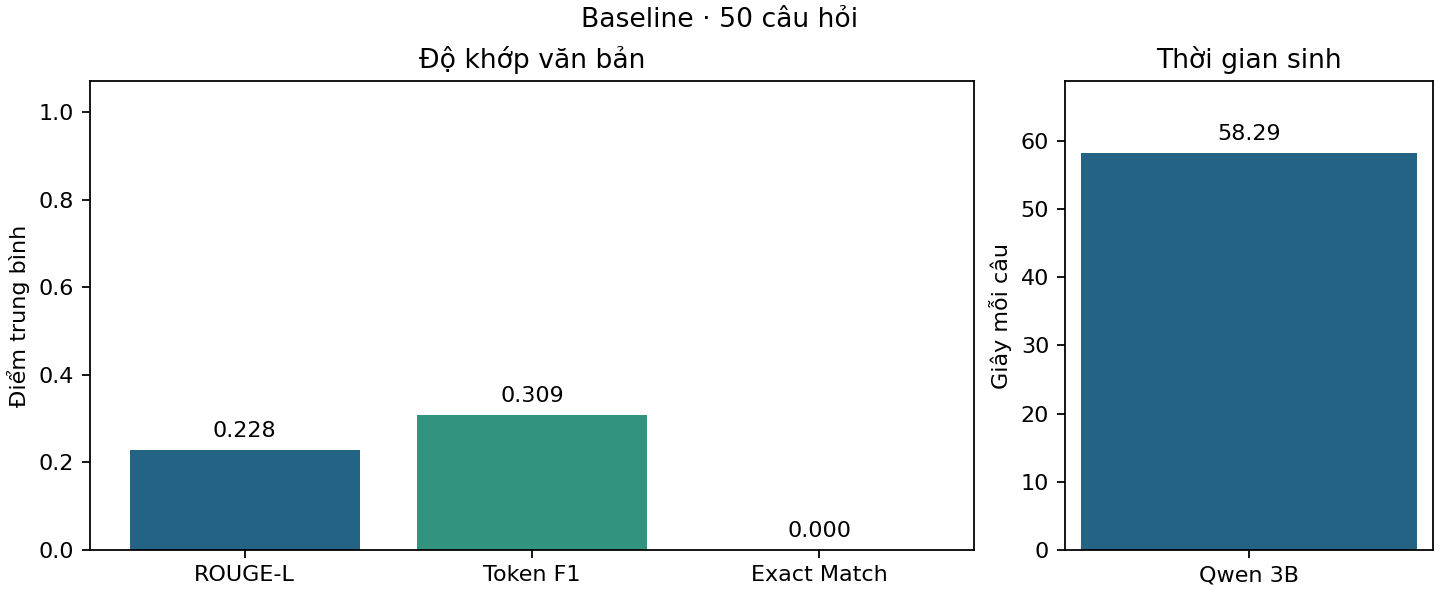

In [4]:
import json
from IPython.display import Image, Markdown, display

BASELINE = RUN_DIR / "baseline"
metrics = json.loads((BASELINE / "baseline_metrics.json").read_text(encoding="utf-8"))
display(Markdown(
    "| Chỉ số | Trung bình |\n|---|---:|\n"
    + "\n".join(f"| {key} | {metrics[key]:.4f} |" for key in ("rouge_l", "token_f1", "exact_match", "inference_time_s"))
))
display(Image(filename=str(RUN_DIR / "figures/baseline_metrics.png")))

## Ví dụ câu trả lời tốt và chưa tốt

Các ví dụ bên dưới lấy từ nhận xét sơ bộ theo từng mẫu nếu đã có tệp nhận xét. Khi chạy trên Colab với gói nguồn, notebook hiển thị sáu ví dụ chọn theo độ khớp văn bản để người đọc đối chiếu. Trạng thái pháp lý vẫn là `unverified` cho tới khi có người chấm độc lập.

In [5]:
import csv

with (BASELINE / "baseline_predictions.csv").open(encoding="utf-8-sig", newline="") as handle:
    predictions = list(csv.DictReader(handle))
by_id = {row["id"]: row for row in predictions}
example_path = BASELINE / "baseline_examples.json"
if example_path.exists():
    selections = json.loads(example_path.read_text(encoding="utf-8"))
else:
    ordered = sorted(predictions, key=lambda row: (float(row["rouge_l"]), row["id"]))
    selections = [
        {"id": row["id"], "category": category, "note": "Ví dụ chọn theo ROUGE-L. Cần đối chiếu pháp lý."}
        for category, rows in (("Độ khớp cao", ordered[-3:][::-1]), ("Độ khớp thấp", ordered[:3]))
        for row in rows
    ]
for example in selections:
    row = by_id[example["id"]]
    print(f"{example['category']} · {row['id']}\n{row['question']}\n")
    print(f"Qwen: {row['base_model_prediction']}\n")
    print(f"Tham chiếu: {row['reference_answer']}\n")
    print(f"Nhận xét: {example['note']}\nNguồn: {row['source_pdf_url']}\n")

Tốt một phần · vn-road-55-80-2
Người có mặt tại nơi xảy ra tai nạn giao thông đường bộ có những trách nhiệm gì?

Qwen: Theo Điều 108 của Luật Giao thông đường bộ năm 2008 và Điều 109 của Luật Giao thông đường bộ năm 2019, người có mặt tại nơi xảy ra tai nạn giao thông đường bộ có trách nhiệm sau:

1. Người có mặt tại nơi xảy ra tai nạn giao thông đường bộ có trách nhiệm báo cho cơ quan có thẩm quyền gần nhất về sự việc. Cụ thể theo Điều 108 của Luật Giao thông đường bộ năm 2008 và Điều 109 của Luật Giao thông đường bộ năm 2019.

2. Người có mặt tại nơi xảy ra tai nạn giao thông đường bộ có trách nhiệm cung cấp thông tin về sự việc cho cơ quan có thẩm quyền. 

3. Người có mặt tại nơi xảy ra tai nạn giao thông đường bộ có trách nhiệm hỗ trợ, giúp đỡ người bị thương hoặc người mất tích. 

4. Người có mặt tại nơi xảy ra tai nạn giao thông đường bộ có trách nhiệm không di chuyển, di dời hoặc tháo gỡ bất kỳ tài sản nào có liên quan đến vụ tai nạn.

Những quy định trên có hiệu

Tham chiếu: Th

## Hạn chế và bàn giao

Bộ test gồm 40 câu tra cứu có gợi căn cứ và 10 câu viết riêng. Các điểm khớp từ bị ảnh hưởng bởi cách diễn đạt, trích dẫn và giới hạn 256 token. Đọc rubric trong `docs/baseline_evaluation.md` và dùng phiếu chấm để xác minh căn cứ, lỗi pháp lý, hallucination và cách từ chối.

In [6]:
if COLAB:
    import shutil
    from google.colab import files
    result_zip = shutil.make_archive("/content/baseline_results", "zip", root_dir=RUN_DIR)
    files.download(result_zip)